In [20]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score


from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix

In [3]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Features Shape :", X.shape)
print("Target Shape :", y.shape)

print("\nClasses:")
print(data.target_names)

Features Shape : (569, 30)
Target Shape : (569,)

Classes:
['malignant' 'benign']


In [4]:
df = pd.DataFrame(X, columns=data.feature_names)

df["Target"] = y

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples :", len(X_train))
print("Testing Samples :", len(X_test))

Training Samples : 455
Testing Samples : 114


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [7]:
mle_model = LogisticRegression(
    penalty=None,
    max_iter=10000
)

mle_model.fit(X_train, y_train)

mle_pred = mle_model.predict(X_test)

In [8]:
print("MLE Results")

print("Accuracy :", accuracy_score(y_test, mle_pred))
print("Precision :", precision_score(y_test, mle_pred))
print("Recall :", recall_score(y_test, mle_pred))
print("F1 Score :", f1_score(y_test, mle_pred))

print("\nConfusion Matrix")

print(confusion_matrix(y_test, mle_pred))

MLE Results
Accuracy : 0.9210526315789473
Precision : 0.9701492537313433
Recall : 0.9027777777777778
F1 Score : 0.9352517985611511

Confusion Matrix
[[40  2]
 [ 7 65]]


In [9]:
map_l2 = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=10000
)

map_l2.fit(X_train, y_train)

l2_pred = map_l2.predict(X_test)

In [10]:
print("MAP (L2) Results")

print("Accuracy :", accuracy_score(y_test, l2_pred))
print("Precision :", precision_score(y_test, l2_pred))
print("Recall :", recall_score(y_test, l2_pred))
print("F1 Score :", f1_score(y_test, l2_pred))

print("\nConfusion Matrix")

print(confusion_matrix(y_test, l2_pred))

MAP (L2) Results
Accuracy : 0.9824561403508771
Precision : 0.9861111111111112
Recall : 0.9861111111111112
F1 Score : 0.9861111111111112

Confusion Matrix
[[41  1]
 [ 1 71]]


In [11]:
map_l1 = LogisticRegression(
    penalty="l1",
    C=1.0,
    solver="liblinear",
    max_iter=10000
)

map_l1.fit(X_train, y_train)

l1_pred = map_l1.predict(X_test)

In [12]:
print("MAP (L1) Results")

print("Accuracy :", accuracy_score(y_test, l1_pred))
print("Precision :", precision_score(y_test, l1_pred))
print("Recall :", recall_score(y_test, l1_pred))
print("F1 Score :", f1_score(y_test, l1_pred))

print("\nConfusion Matrix")

print(confusion_matrix(y_test, l1_pred))

MAP (L1) Results
Accuracy : 0.9912280701754386
Precision : 0.9863013698630136
Recall : 1.0
F1 Score : 0.993103448275862

Confusion Matrix
[[41  1]
 [ 0 72]]


In [13]:
results = pd.DataFrame({

    "Model":[
        "MLE",
        "MAP L2",
        "MAP L1"
    ],

    "Accuracy":[
        accuracy_score(y_test,mle_pred),
        accuracy_score(y_test,l2_pred),
        accuracy_score(y_test,l1_pred)
    ],

    "Precision":[
        precision_score(y_test,mle_pred),
        precision_score(y_test,l2_pred),
        precision_score(y_test,l1_pred)
    ],

    "Recall":[
        recall_score(y_test,mle_pred),
        recall_score(y_test,l2_pred),
        recall_score(y_test,l1_pred)
    ],

    "F1 Score":[
        f1_score(y_test,mle_pred),
        f1_score(y_test,l2_pred),
        f1_score(y_test,l1_pred)
    ]

})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,MLE,0.921053,0.970149,0.902778,0.935252
1,MAP L2,0.982456,0.986111,0.986111,0.986111
2,MAP L1,0.991228,0.986301,1.000000,0.993103


In [14]:
coef = pd.DataFrame({

    "Feature":data.feature_names,

    "MLE":mle_model.coef_[0],

    "MAP_L2":map_l2.coef_[0],

    "MAP_L1":map_l1.coef_[0]

})

coef

,Feature,MLE,MAP_L2,MAP_L1
0,mean radius,45.606989,-0.505070,0.000000
1,mean texture,-274.776451,-0.558734,-0.398051
2,mean perimeter,39.418899,-0.471408,0.000000
3,mean area,-100.907767,-0.538737,0.000000
4,mean smoothness,-147.564415,-0.207718,0.000000
5,mean compactness,974.960203,0.653627,0.000000
6,mean concavity,-263.071371,-0.606579,0.000000
7,mean concave points,-84.661408,-0.700013,-0.489638
8,mean symmetry,-53.992504,-0.172986,0.000000
9,mean fractal dimension,-286.841896,0.193609,0.078706


In [15]:
coef.head(15)

,Feature,MLE,MAP_L2,MAP_L1
0,mean radius,45.606989,-0.505070,0.000000
1,mean texture,-274.776451,-0.558734,-0.398051
2,mean perimeter,39.418899,-0.471408,0.000000
3,mean area,-100.907767,-0.538737,0.000000
4,mean smoothness,-147.564415,-0.207718,0.000000
5,mean compactness,974.960203,0.653627,0.000000
6,mean concavity,-263.071371,-0.606579,0.000000
7,mean concave points,-84.661408,-0.700013,-0.489638
8,mean symmetry,-53.992504,-0.172986,0.000000
9,mean fractal dimension,-286.841896,0.193609,0.078706


In [16]:
print("Zero Coefficients")

print("MLE :", np.sum(mle_model.coef_[0] == 0))

print("MAP L2 :", np.sum(map_l2.coef_[0] == 0))

print("MAP L1 :", np.sum(map_l1.coef_[0] == 0))

Zero Coefficients
MLE : 0
MAP L2 : 0
MAP L1 : 14


In [17]:
print("Conclusion")

print("- MLE uses Maximum Likelihood Estimation without regularization.")
print("- MAP L2 uses Gaussian Prior and shrinks coefficients.")
print("- MAP L1 uses Laplace Prior and performs feature selection.")
print("- L1 may produce zero coefficients.")
print("- L2 usually gives smoother coefficient estimates.")
print("- Regularization reduces overfitting and improves generalization.")

Conclusion
- MLE uses Maximum Likelihood Estimation without regularization.
- MAP L2 uses Gaussian Prior and shrinks coefficients.
- MAP L1 uses Laplace Prior and performs feature selection.
- L1 may produce zero coefficients.
- L2 usually gives smoother coefficient estimates.
- Regularization reduces overfitting and improves generalization.


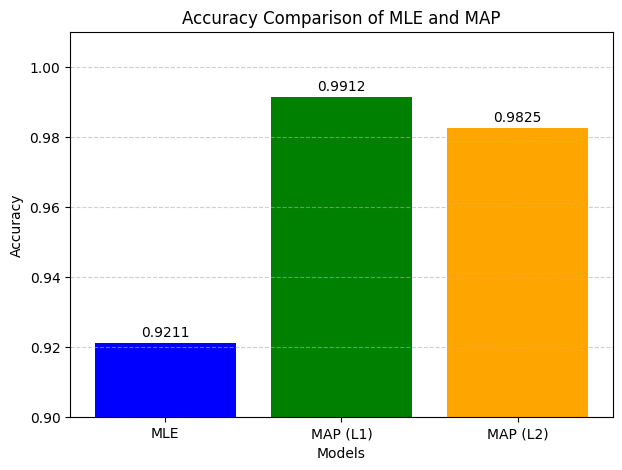

In [21]:
# Calculate accuracies
acc_mle = accuracy_score(y_test, mle_pred)
acc_l1 = accuracy_score(y_test, l1_pred)
acc_l2 = accuracy_score(y_test, l2_pred)

# Data for plotting
models = ["MLE", "MAP (L1)", "MAP (L2)"]
accuracies = [acc_mle, acc_l1, acc_l2]

# Plot
plt.figure(figsize=(7,5))
bars = plt.bar(models, accuracies, color=["blue", "green", "orange"])

plt.title("Accuracy Comparison of MLE and MAP")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0.90, 1.01)

# Display accuracy values on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 0.002,
             f"{height:.4f}",
             ha="center",
             fontsize=10)

plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()


In [23]:
from sklearn.linear_model import LogisticRegression

mle = LogisticRegression(
    penalty=None,
    max_iter=10000,
    random_state=42
)

mle.fit(X_train, y_train)

mle_pred = mle.predict(X_test)

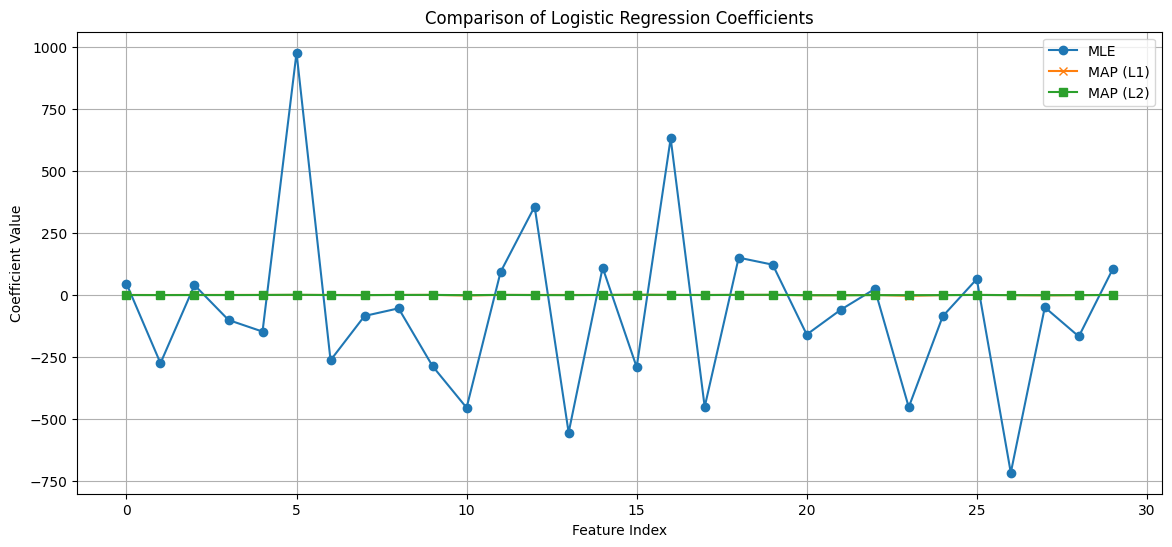

In [24]:
import numpy as np
import matplotlib.pyplot as plt

coef_mle = mle.coef_[0]
coef_l1 = map_l1.coef_[0]
coef_l2 = map_l2.coef_[0]

x = np.arange(len(coef_mle))

plt.figure(figsize=(14,6))

plt.plot(x, coef_mle, marker='o', label='MLE')
plt.plot(x, coef_l1, marker='x', label='MAP (L1)')
plt.plot(x, coef_l2, marker='s', label='MAP (L2)')

plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.title("Comparison of Logistic Regression Coefficients")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
0